<a href="https://colab.research.google.com/github/wadeea23/Age-Prediction/blob/main/wadeea_lab_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os ,glob
import zipfile
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from keras.utils import to_categorical
from keras.models import Sequential
from keras.layers import Dense, Input, Activation, Flatten , Conv2D, MaxPooling2D
from keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report ,recall_score


**part 1**

In [54]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [55]:
zip_path = "/content/drive/MyDrive/GA/labCNN/labCNN.zip"
extract_path = "/content/labCNN"

In [56]:
with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print(os.listdir(extract_path))

['crop_part1', 'UTKFace', 'utkface_aligned_cropped']


In [57]:
images_path = "/content/labCNN/UTKFace"
paths = glob.glob(os.path.join(images_path, "**", "*.jpg"), recursive=True)
print("Total images:", len(paths))

Total images: 23708


In [58]:
ages = []

for p in paths:
    name = os.path.basename(p)
    age = int(name.split("_")[0])
    ages.append(age)

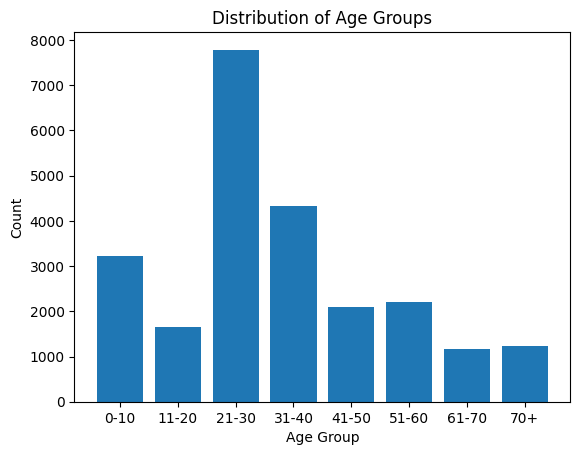

In [59]:
bins = [0, 10, 20, 30, 40, 50, 60, 70, 120]
labels = ["0-10", "11-20", "21-30", "31-40", "41-50", "51-60", "61-70", "70+"]

age_groups = pd.cut(ages, bins=bins, labels=labels)
counts = age_groups.value_counts().sort_index()

plt.bar(counts.index, counts.values)
plt.xlabel("Age Group")
plt.ylabel("Count")
plt.title("Distribution of Age Groups")
plt.show()


- The data is imbalanced: the 21-30 age group has the most images, while the other age groups especially 61-70 and 70+ have far fewer images.


In [60]:
X = []
y = []

for p in paths:
    age = int(os.path.basename(p).split("_")[0])

    img = Image.open(p)
    img = img.resize((48, 48))

    X.append(np.array(img))
    y.append(age)

X = np.array(X)
y = np.array(y)

print(X.shape, y.shape)

(23708, 48, 48, 3) (23708,)


In [61]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

print(X_train.shape, X_val.shape, X_test.shape)

(15172, 48, 48, 3) (3794, 48, 48, 3) (4742, 48, 48, 3)


In [62]:
#normalized to 0,1
X_train=X_train/255
X_val=X_val/255
X_test=X_test/255
print(X_train.min(), X_train.max())

0.0 1.0


**PART 2**
Neural Network

In [63]:
model = Sequential()
model.add(Input(shape=(48, 48,3)))

model.add(Conv2D(32, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))

model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))

model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))

model.add(Conv2D(256, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))


model.add(Flatten())
model.add(Dense(1))


In [64]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 46, 46, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 21, 21, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 2, 2, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 1, 1, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 388,673 (1.48 MB)

 Trainable params: 388,673 (1.48 MB)

 Non-trainable params: 0 (0.00 B)

In [65]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['mae'])

In [66]:
history = model.fit(X_train, y_train, epochs=10, batch_size=32,validation_split=0.2,shuffle=False)

Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/losses/losses.py:33: SyntaxWarning: In loss categorical_crossentropy, expected y_pred.shape to be (batch_size, num_classes) with num_classes > 1. Received: y_pred.shape=(None, 1). Consider using 'binary_crossentropy' if you only have 2 classes.
  return self.fn(y_true, y_pred, **self._fn_kwargs)


380/380 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - loss: 3.9584e-06 - mae: 33.3104 - val_loss: 3.9193e-06 - val_mae: 33.1917
Epoch 2/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 3.9584e-06 - mae: 33.5055 - val_loss: 3.9193e-06 - val_mae: 33.0329
Epoch 3/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 3.9584e-06 - mae: 33.1295 - val_loss: 3.9193e-06 - val_mae: 32.7375
Epoch 4/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 3.9584e-06 - mae: 33.0648 - val_loss: 3.9193e-06 - val_mae: 32.7375
Epoch 5/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 3.9584e-06 - mae: 33.2175 - val_loss: 3.9193e-06 - val_mae: 32.8775
Epoch 6/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 3.9584e-06 - mae: 46.1064 - val_loss: 3.9193e-06 - val_mae: 49.8440
Epoch 7/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 3.9584e-06 - mae: 50.2462 - val_loss: 3.9193e-06 - val_mae: 49.8440
Epoch 8/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 3.9584e-06 - mae: 50.2462 - val_loss: 3.9193e-06 - val

<Axes: >

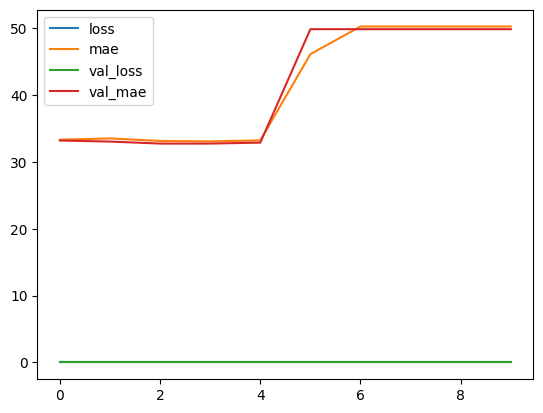

In [67]:
pd.DataFrame(history.history).plot()

In [68]:
teat_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", teat_loss)

149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 4.0084e-06 - mae: 50.6335
Test Accuracy: 50.633514404296875
Test Loss: 4.008393716503633e-06


In [69]:
confusion_matrix(y_test, np.argmax(model.predict(X_test), axis=1))

149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


array([[  0,   0,   0, ...,   0,   0,   0],
       [229,   0,   0, ...,   0,   0,   0],
       [108,   0,   0, ...,   0,   0,   0],
       ...,
       [  1,   0,   0, ...,   0,   0,   0],
       [  2,   0,   0, ...,   0,   0,   0],
       [  1,   0,   0, ...,   0,   0,   0]])

In [70]:
classification_report(y_test, np.argmax(model.predict(X_test), axis=1))

149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_

'              precision    recall  f1-score   support\n\n           0       0.00      0.00      0.00       0.0\n           1       0.00      0.00      0.00     229.0\n           2       0.00      0.00      0.00     108.0\n           3       0.00      0.00      0.00      61.0\n           4       0.00      0.00      0.00      50.0\n           5       0.00      0.00      0.00      41.0\n           6       0.00      0.00      0.00      16.0\n           7       0.00      0.00      0.00      28.0\n           8       0.00      0.00      0.00      62.0\n           9       0.00      0.00      0.00      27.0\n          10       0.00      0.00      0.00      32.0\n          11       0.00      0.00      0.00      15.0\n          12       0.00      0.00      0.00      30.0\n          13       0.00      0.00      0.00      18.0\n          14       0.00      0.00      0.00      28.0\n          15       0.00      0.00      0.00      34.0\n          16       0.00      0.00      0.00      41.0\n       

In [71]:
recall_score(y_test, np.argmax(model.predict(X_test), axis=1), average=None)

149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

**part 3 **

149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


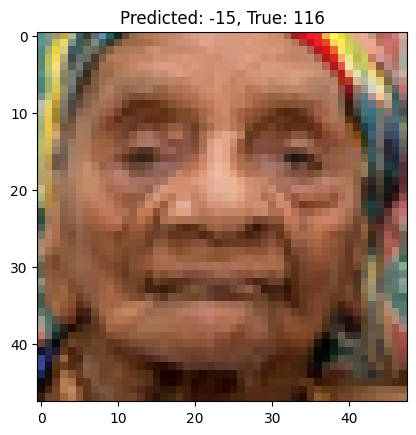

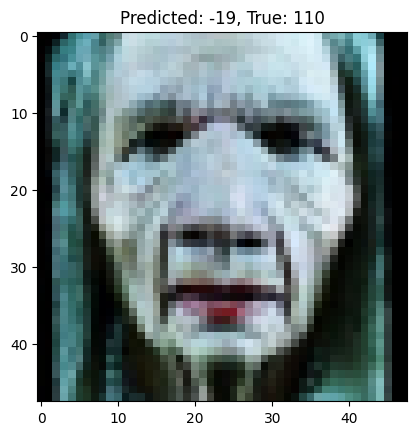

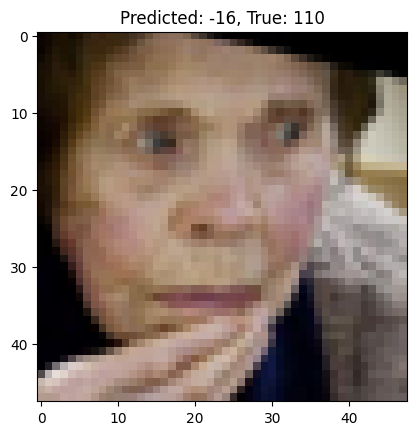

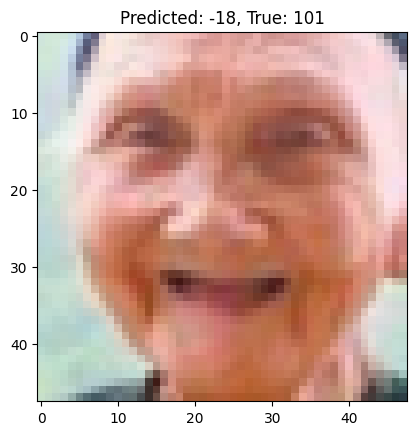

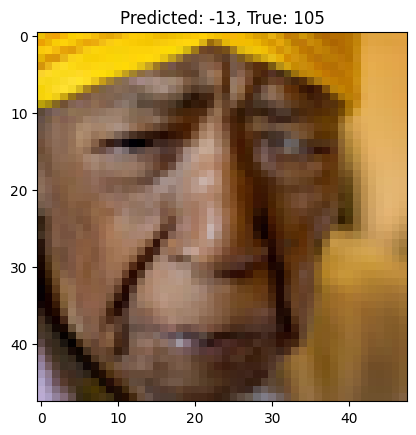

In [72]:
y_pred = model.predict(X_test).flatten()

error = abs(y_pred - np.array(y_test))
worst = np.argsort(error)[::-1]

for i in worst[:5]:
    plt.imshow(X_test[i])
    plt.title("Predicted: " + str(round(y_pred[i])) +
              ", True: " + str(y_test[i]))
    plt.show()

The model made mistakes because age is difficult to predict from faces, and image quality and unbalanced age groups can affect accuracy.

In [80]:
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

In [81]:
history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_data=(X_val, y_val), callbacks=[early_stopping])

Epoch 1/10
475/475 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - loss: 3.9505e-06 - mae: 50.1658 - val_loss: 4.0003e-06 - val_mae: 50.5358
Epoch 2/10
475/475 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - loss: 3.9505e-06 - mae: 50.1658 - val_loss: 4.0003e-06 - val_mae: 50.5358
Epoch 3/10
475/475 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 3.9505e-06 - mae: 50.1658 - val_loss: 4.0003e-06 - val_mae: 50.5358
Epoch 4/10
475/475 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 3.9505e-06 - mae: 50.1657 - val_loss: 4.0003e-06 - val_mae: 50.5358
Epoch 5/10
475/475 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 3.9505e-06 - mae: 50.1658 - val_loss: 4.0003e-06 - val_mae: 50.5358
Epoch 6/10
475/475 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 3.9505e-06 - mae: 50.1658 - val_loss: 4.0003e-06 - val_mae: 50.5358


In [82]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 4.0084e-06 - mae: 50.6335
Test Accuracy: 50.633514404296875
Test Loss: 4.008393716503633e-06


**part 4**

In [76]:
!pip install streamlit pyngrok

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 104.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 131.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [streamlit]


In [77]:
%%writefile /content/age_app.py

import streamlit as st
import numpy as np
from PIL import Image
from tensorflow.keras.models import load_model

model = load_model("/content/age_model.keras")

st.title("Age Estimator")

uploaded_image = st.file_uploader("Upload Image", type=["jpg", "jpeg", "png"])

open_camera = st.checkbox("Open Camera")

camera_image = None

if open_camera:
    camera_image = st.camera_input("Take a Photo")

if uploaded_image is not None:
    image_file = uploaded_image
elif camera_image is not None:
    image_file = camera_image
else:
    image_file = None

if image_file is not None:
    image = Image.open(image_file)
    st.image(image)

    if st.button("Predict Age"):
        image = image.convert("RGB").resize((48, 48))
        image = np.array(image) / 255.0
        image = np.expand_dims(image, axis=0)

        prediction = model.predict(image, verbose=0)
        age = round(prediction[0][0])

        st.success(f"Estimated Age: {age} years old")


Writing /content/age_app.py


In [78]:
!streamlit run /content/age_app.py --server.port 8501 &>/content/logs.txt &
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴⠦⠧Need to install the following packages:
localtunnel@2.0.2
Ok to proceed? (y) ^C


In [79]:
model.save("/content/age_model.keras")